# Week 02 · Machine Learning
# Logistic Regression & Classification Fundamentals

**Program:** Data Science & AI — 200-hour professional program  
**Business case:** AdventureWorks  
**Estimated classroom time:** 5 hours  
**Level:** Beginner to early intermediate  
**Language:** B2 English  
**Notebook ID:** ML_10

---

## Instructor and learner guide

This notebook introduces **binary classification** through a practical business question: *Can AdventureWorks estimate whether an order is likely to be returned?*

The notebook uses deterministic synthetic data. It is designed for classroom learning and does not represent real customer behaviour.

- **Concept** explains the idea and why it matters.
- **Demonstration** provides runnable Python code.
- **Your turn** gives learners a focused task.
- **Instructor solution** appears in a clearly separated section near the end.

> **Scope note:** This notebook focuses on classification foundations and Logistic Regression. It does not repeat the detailed regression workflow, model validation, cross-validation, tree models, or hyperparameter optimization taught elsewhere in the program.

## Learning outcomes

By the end of this session, learners should be able to:

1. Distinguish classification from regression and define a binary classification problem.
2. Define a target label and select features available at the prediction time.
3. Explain the intuition behind a probability, the sigmoid function, and a decision threshold.
4. Train a Logistic Regression classifier using scikit-learn.
5. Explain why numeric scaling and categorical encoding are needed.
6. Interpret predicted probabilities and class predictions correctly.
7. Read a confusion matrix and explain accuracy, precision, recall, and F1-score.
8. Explain ROC curves and ROC-AUC at an introductory level.
9. Discuss threshold trade-offs in a business context.
10. Build and communicate a small end-to-end classification solution.

### Suggested 5-hour delivery plan

| Block | Focus | Time |
|---|---|---:|
| 1 | Business problem, labels, features, and data inspection | 40 min |
| 2 | Classification probabilities and Logistic Regression intuition | 55 min |
| 3 | Preprocessing and model training | 55 min |
| 4 | Predictions, confusion matrix, and classification metrics | 70 min |
| 5 | Threshold selection and ROC-AUC | 45 min |
| 6 | Mini project, knowledge check, and review | 55 min |

## Table of contents

1. The business problem: predicting order returns
2. Build and inspect the AdventureWorks dataset
3. Define the target and eligible features
4. Classification: labels, probabilities, and decisions
5. Logistic Regression intuition
6. Prepare data with a preprocessing pipeline
7. Train a Logistic Regression classifier
8. Predict classes and probabilities
9. Evaluate with a confusion matrix
10. Understand precision, recall, F1, and ROC-AUC
11. Choose a decision threshold for the business
12. Common mistakes and responsible interpretation
13. Mini project: prioritize orders for return-risk review
14. Knowledge check and readiness checklist
15. Instructor solutions

# 1. The business problem: predicting order returns

AdventureWorks wants to identify orders that may be returned so that the operations team can review patterns, improve product information, and plan support capacity.

The model's target is **`returned`**:

- `1` means the order was returned.
- `0` means the order was not returned.

This is a **binary classification** problem because the model predicts one of two classes.

### Classification vs. regression

| Task | Example question | Output |
|---|---|---|
| Regression | What will the order revenue be? | A numeric value, such as 245.50 |
| Classification | Will the order be returned? | A class, such as 0 or 1 |

The business question determines the problem type. Choose the target first; then decide which features are appropriate.

### Define the prediction moment

For this exercise, assume the model runs **when an order is placed**. It may use information known at that moment, such as:

- order value and item quantity
- discount percentage
- product category
- sales channel
- customer segment and tenure
- payment method
- destination region

It must not use information created later, such as actual delivery delay, refund amount, return reason, or final return status. Those fields would leak information about the outcome.

### Exercise 1 — Frame the business problem

1. Why is predicting a return a classification problem?
2. What does class `1` represent in this notebook?
3. Name two features that are available at order placement.
4. Why should `refund_amount` not be used as a feature?
5. Who could use the model's risk scores, and what action might they take?

Write your answers in your own words before continuing.

# 2. Build and inspect the AdventureWorks dataset

We will create a compact synthetic dataset with realistic business columns. A fixed random seed makes the results reproducible.

The data includes a few missing values so that the preprocessing pipeline can demonstrate imputation. The target is generated from a plausible pattern with noise; it is not a rule that should be treated as a real-world truth.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

n_orders = 2400

product_category = rng.choice(
    ["Electronics", "Home", "Accessories", "Office"],
    size=n_orders,
    p=[0.34, 0.27, 0.24, 0.15]
)
sales_channel = rng.choice(
    ["Website", "Mobile App", "Store", "Partner"],
    size=n_orders,
    p=[0.38, 0.30, 0.20, 0.12]
)
customer_segment = rng.choice(
    ["Consumer", "Small Business", "Corporate"],
    size=n_orders,
    p=[0.62, 0.23, 0.15]
)
payment_method = rng.choice(
    ["Card", "Digital Wallet", "Bank Transfer", "Cash on Delivery"],
    size=n_orders,
    p=[0.48, 0.27, 0.13, 0.12]
)
region = rng.choice(
    ["North", "South", "East", "West"],
    size=n_orders
)

quantity = rng.integers(1, 8, size=n_orders)
unit_price = np.round(rng.lognormal(mean=3.7, sigma=0.65, size=n_orders), 2)
discount_pct = np.round(rng.choice([0, 0.05, 0.10, 0.15, 0.20], size=n_orders,
                                  p=[0.40, 0.18, 0.22, 0.13, 0.07]), 2)
customer_tenure_months = rng.integers(1, 97, size=n_orders)
prior_orders = rng.poisson(lam=5, size=n_orders)
days_since_last_order = rng.integers(1, 181, size=n_orders)

order_value = quantity * unit_price * (1 - discount_pct)

# Construct a synthetic return tendency using known-at-order features.
logit = (
    -2.15
    + 0.48 * (product_category == "Electronics")
    + 0.38 * (payment_method == "Cash on Delivery")
    + 0.30 * (sales_channel == "Partner")
    + 0.018 * (discount_pct * 100)
    + 0.0009 * np.maximum(order_value - 150, 0)
    - 0.018 * np.minimum(customer_tenure_months, 36)
    - 0.075 * np.minimum(prior_orders, 8)
    + 0.002 * days_since_last_order
    + rng.normal(0, 0.55, size=n_orders)
)
probability = 1 / (1 + np.exp(-logit))
returned = rng.binomial(1, probability)

orders = pd.DataFrame({
    "order_id": [f"AW-{50000+i}" for i in range(n_orders)],
    "product_category": product_category,
    "sales_channel": sales_channel,
    "customer_segment": customer_segment,
    "payment_method": payment_method,
    "region": region,
    "quantity": quantity,
    "unit_price": unit_price,
    "discount_pct": discount_pct,
    "order_value": np.round(order_value, 2),
    "customer_tenure_months": customer_tenure_months,
    "prior_orders": prior_orders,
    "days_since_last_order": days_since_last_order,
    "returned": returned
})

# Add a small number of missing feature values for pipeline practice.
for column, count in [("unit_price", 28), ("customer_segment", 22),
                      ("days_since_last_order", 18)]:
    missing_rows = rng.choice(orders.index, size=count, replace=False)
    orders.loc[missing_rows, column] = np.nan

display(orders.head())
print(f"Rows: {len(orders):,}")
print(f"Columns: {orders.shape[1]}")

,order_id,product_category,sales_channel,customer_segment,payment_method,region,quantity,unit_price,discount_pct,order_value,customer_tenure_months,prior_orders,days_since_last_order,returned
0,AW-50000,Accessories,Mobile App,Consumer,Card,North,1,48.48,0.0,48.48,41,8,180.0,0
1,AW-50001,Home,Store,Consumer,Card,East,1,18.40,0.2,14.72,6,8,120.0,0
2,AW-50002,Office,Store,Consumer,Card,West,6,31.09,0.0,186.54,59,6,168.0,0
3,AW-50003,Accessories,Partner,Consumer,Cash on Delivery,North,2,26.72,0.0,53.44,62,3,29.0,0
4,AW-50004,Electronics,Store,Small Business,Digital Wallet,North,1,21.31,0.0,21.31,65,6,30.0,1


Rows: 2,400
Columns: 14


### Inspect the data

A first inspection helps us understand the table before modeling. Check column types, missing values, and the target distribution.

In [2]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_id                2400 non-null   object 
 1   product_category        2400 non-null   object 
 2   sales_channel           2400 non-null   object 
 3   customer_segment        2378 non-null   object 
 4   payment_method          2400 non-null   object 
 5   region                  2400 non-null   object 
 6   quantity                2400 non-null   int64  
 7   unit_price              2372 non-null   float64
 8   discount_pct            2400 non-null   float64
 9   order_value             2400 non-null   float64
 10  customer_tenure_months  2400 non-null   int64  
 11  prior_orders            2400 non-null   int64  
 12  days_since_last_order   2382 non-null   float64
 13  returned                2400 non-null   int64  
dtypes: float64(4), int64(4), object(6)
memor

In [3]:
display(orders.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,2400,2400,AW-50000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,2400,4,Electronics,834,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sales_channel,2400,4,Website,928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,2378,3,Consumer,1501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,2400,4,Card,1120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,2400,4,East,616,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,2400.0,NaN,NaN,NaN,4.043333,2.003071,1.0,2.0,4.0,6.0,7.0
unit_price,2372.0,NaN,NaN,NaN,49.664895,36.130099,3.23,26.24,39.965,61.0475,303.51
discount_pct,2400.0,NaN,NaN,NaN,0.066396,0.065436,0.0,0.0,0.05,0.1,0.2
order_value,2400.0,NaN,NaN,NaN,186.937537,179.426892,7.44,71.995,133.365,236.49,1487.99


,count,share
returned,,
Not returned (0),2149,0.895417
Returned (1),251,0.104583


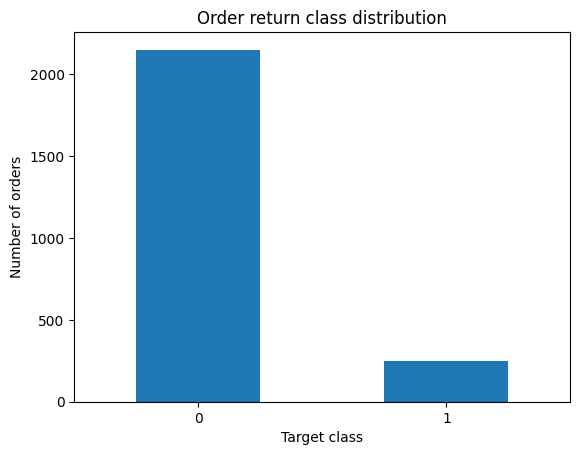

In [4]:
target_counts = orders["returned"].value_counts().sort_index()
target_rates = orders["returned"].value_counts(normalize=True).sort_index()

display(pd.DataFrame({
    "count": target_counts,
    "share": target_rates
}).rename(index={0: "Not returned (0)", 1: "Returned (1)"}))

target_counts.plot(kind="bar", title="Order return class distribution")
plt.xlabel("Target class")
plt.ylabel("Number of orders")
plt.xticks(rotation=0)
plt.show()

### Interpret the target distribution

The target distribution shows how many examples belong to each class. If one class is much more common, a model can achieve high accuracy by predicting the majority class too often.

This is called **class imbalance**. We will not apply advanced resampling methods here; first, learn to inspect the distribution and choose metrics that reveal performance on both classes.

### Exercise 2 — Data inspection

1. How many orders are in the dataset?
2. Which columns contain missing values?
3. Which class is more common?
4. Why is the target distribution important?
5. Identify two numeric and two categorical features.

**Stretch:** Calculate the percentage of returned orders without using the printed chart.

# 3. Define the target and eligible features

In supervised learning:

- `X` contains the input features.
- `y` contains the target labels.

We exclude `order_id` because it is an identifier, not a meaningful order behaviour. We also do not create post-outcome columns such as `refund_amount` or `return_reason`.

A professional feature decision always considers the **prediction time**: would this value genuinely be available when the model needs to make its prediction?

In [5]:
target = "returned"

numeric_features = [
    "quantity",
    "unit_price",
    "discount_pct",
    "order_value",
    "customer_tenure_months",
    "prior_orders",
    "days_since_last_order"
]

categorical_features = [
    "product_category",
    "sales_channel",
    "customer_segment",
    "payment_method",
    "region"
]

feature_columns = numeric_features + categorical_features

X = orders[feature_columns].copy()
y = orders[target].copy()

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("Target classes:", sorted(y.unique()))

Feature matrix: (2400, 12)
Target vector: (2400,)
Target classes: [np.int64(0), np.int64(1)]


### Exercise 3 — Feature selection

1. Why is `order_id` excluded?
2. Would `return_reason` be a valid feature at order placement? Explain.
3. Add one hypothetical feature that could be valid if it is known before checkout.
4. Explain the difference between a feature and a target.

Do not add a feature simply because it is available in the final historical table. Check when it became known.

# 4. Classification: labels, probabilities, and decisions

A classifier can provide two related outputs:

1. **Predicted probability:** how strongly the model estimates that an observation belongs to a class.
2. **Predicted class:** the label selected after applying a decision threshold.

For example, a model may estimate a 0.78 probability of return. With a threshold of 0.50, it predicts class `1`. With a threshold of 0.80, it predicts class `0`.

The probability is not a guarantee. It is a model estimate and should be evaluated on unseen data.

### The sigmoid function

Logistic Regression first calculates a score from the input features. The sigmoid function maps that score to a value between 0 and 1:

\[
\sigma(z) = \frac{1}{1 + e^{-z}}
\]

A value near 0 indicates a low estimated probability for the positive class; a value near 1 indicates a high estimated probability.

The curve is smooth. It does not mean that every business relationship is truly shaped like an S-curve; it is the mathematical link used by Logistic Regression.

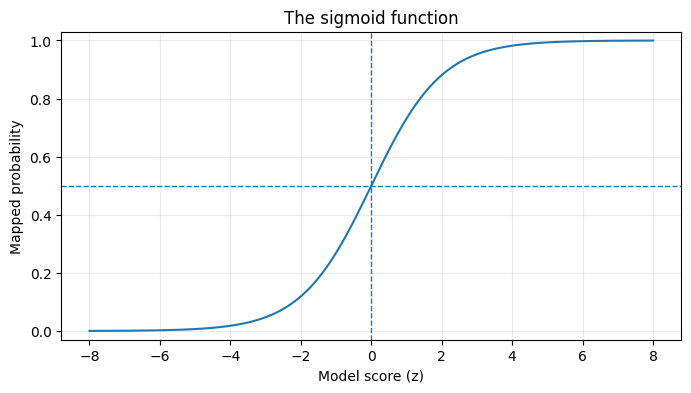

In [6]:
z = np.linspace(-8, 8, 300)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 4))
plt.plot(z, sigmoid)
plt.axhline(0.5, linestyle="--", linewidth=1)
plt.axvline(0, linestyle="--", linewidth=1)
plt.title("The sigmoid function")
plt.xlabel("Model score (z)")
plt.ylabel("Mapped probability")
plt.ylim(-0.03, 1.03)
plt.grid(alpha=0.25)
plt.show()

### A decision threshold

A threshold converts a probability into a class. The default threshold for `predict()` in a binary scikit-learn classifier is usually 0.5.

- If probability is greater than or equal to the threshold, predict class `1`.
- Otherwise, predict class `0`.

The threshold is a decision choice. It should reflect the cost of different mistakes, not be selected only because 0.5 is familiar.

In [7]:
example_probabilities = np.array([0.12, 0.43, 0.51, 0.67, 0.91])

for threshold in [0.30, 0.50, 0.70]:
    predicted_labels = (example_probabilities >= threshold).astype(int)
    print(f"Threshold {threshold:.2f}: {predicted_labels}")

Threshold 0.30: [0 1 1 1 1]
Threshold 0.50: [0 0 1 1 1]
Threshold 0.70: [0 0 0 0 1]


### Exercise 4 — Probability and threshold

1. What is the difference between a probability and a predicted class?
2. At a threshold of 0.50, what class is predicted for probability 0.49?
3. What happens to the number of positive predictions when the threshold increases?
4. Why might a returns team prefer a lower threshold?
5. Why could a lower threshold create extra work?

**Discussion:** Is a probability of 0.80 the same as an 80% certainty that this individual order will be returned? Explain why not.

# 5. Logistic Regression intuition

Despite the word *Regression* in its name, Logistic Regression is commonly used for classification.

For binary classification, it models the log-odds of the positive class as a linear combination of the features:

\[
\log\left(\frac{p}{1-p}\right)
= \beta_0 + \beta_1x_1 + \cdots + \beta_kx_k
\]

The sigmoid function converts this linear score into a probability.

### What the coefficients mean

- A positive coefficient increases the model's estimated log-odds for class `1`, holding other inputs constant.
- A negative coefficient decreases the estimated log-odds for class `1`, holding other inputs constant.
- A coefficient is not automatically a causal effect.
- The size of a coefficient depends on the feature's scale and encoding.

For a one-unit increase in a numeric feature, `exp(coefficient)` is the multiplicative change in the odds, holding other modeled features constant. This interpretation requires care, especially after scaling or one-hot encoding.

### Odds are not the same as probability

If the probability is 0.80, the odds are:

\[
\frac{0.80}{1-0.80}=4
\]

This means four positive outcomes for each one negative outcome in odds terms. It does not mean a 4% probability.

We do not need to calculate log-odds by hand to use scikit-learn, but understanding the idea helps explain what Logistic Regression learns.

### Exercise 5 — Interpret the model

1. Why is Logistic Regression still a classification algorithm?
2. What does a positive coefficient indicate?
3. Why should we avoid saying that a feature *causes* returns based only on a fitted coefficient?
4. If odds are 2, what is the corresponding probability?

**Hint:** Convert odds to probability using `odds / (1 + odds)`.

# 6. Prepare data with a preprocessing pipeline

Logistic Regression works with numeric input. Our dataset contains both numeric and categorical columns, plus missing values.

We will use:

- median imputation for numeric features
- most-frequent imputation for categorical features
- standard scaling for numeric features
- one-hot encoding for categorical features
- a scikit-learn `Pipeline` to keep transformations and the classifier together

The preprocessing steps are fitted on the training data only. This helps prevent information from the test set from influencing the training process.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training class share:")
display(y_train.value_counts(normalize=True).rename("share"))
print("Test class share:")
display(y_test.value_counts(normalize=True).rename("share"))

Training rows: 1800
Test rows: 600
Training class share:


returned
0    0.895556
1    0.104444
Name: share, dtype: float64

Test class share:


returned
0    0.895
1    0.105
Name: share, dtype: float64

### Why use `stratify=y`?

A stratified split aims to preserve the target class proportions in both subsets. This is useful when one class is less common.

It does not guarantee that every future sample will have the same distribution. It simply makes the split more representative of the full dataset's class balance.

In [9]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

logistic_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differen

### Exercise 6 — Pipeline design

1. Why do we impute missing values?
2. Why is scaling useful for Logistic Regression?
3. Why do we encode categorical variables?
4. What problem does `handle_unknown="ignore"` help manage?
5. Why should the preprocessing steps be inside the pipeline?

**Stretch:** Explain why we do not fit the scaler on the complete dataset before splitting.

# 7. Train a Logistic Regression classifier

Training means calling `fit()` with the training features and their known labels. The model estimates coefficients that help separate the two classes.

We use `max_iter=1000` to allow enough optimization iterations for the solver to converge on this dataset. If a convergence warning appears on another dataset, investigate scaling, feature quality, solver choice, and iteration settings rather than simply hiding the warning.

In [10]:
logistic_model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


### What did the model learn?

The model learned a set of coefficients from the training data. It did not memorize a business rule written by us. It estimates patterns that help distinguish returned from non-returned orders.

A fitted model is not automatically useful. We must evaluate it on data that was not used to fit it.

### Exercise 7 — Training process

1. What data is passed to `fit()`?
2. Why do we not pass `y_test` to `fit()`?
3. Does successful training prove that the model will perform well on new orders?
4. What would you investigate if the model did not converge?

# 8. Predict classes and probabilities

Use `predict()` to obtain class labels. Use `predict_proba()` to obtain estimated probabilities for each class.

For a binary classifier, the columns returned by `predict_proba()` follow the order in `classes_`. Always check the class order rather than assuming that column 1 always represents the positive class.

In [11]:
class_order = logistic_model.named_steps["classifier"].classes_
print("Class order:", class_order)

class_predictions = logistic_model.predict(X_test)
probability_matrix = logistic_model.predict_proba(X_test)

positive_class_index = list(class_order).index(1)
return_probabilities = probability_matrix[:, positive_class_index]

prediction_preview = X_test.head(10).copy()
prediction_preview["actual_returned"] = y_test.loc[prediction_preview.index]
prediction_preview["predicted_class"] = class_predictions[:10]
prediction_preview["return_probability"] = return_probabilities[:10]

display(prediction_preview[[
    "product_category", "sales_channel", "order_value",
    "actual_returned", "predicted_class", "return_probability"
]].round(3))

Class order: [0 1]


,product_category,sales_channel,order_value,actual_returned,predicted_class,return_probability
1883,Accessories,Website,164.79,0,0,0.040
766,Electronics,Website,69.94,0,0,0.121
2303,Home,Website,157.44,1,0,0.112
982,Accessories,Partner,127.94,0,0,0.036
1352,Electronics,Mobile App,262.66,0,0,0.156
1590,Electronics,Partner,433.06,0,0,0.178
1131,Home,Website,210.61,0,0,0.084
1128,Accessories,Store,265.92,0,0,0.042
2263,Electronics,Website,227.29,0,0,0.175
470,Home,Mobile App,31.77,0,0,0.077


### Exercise 8 — Read model predictions

1. Which method returns class labels?
2. Which method returns probabilities?
3. Why do we inspect `classes_`?
4. Find one order where the predicted probability is close to 0.50. What does that tell you?
5. Does a high predicted probability guarantee a return?

# 9. Evaluate with a confusion matrix

A confusion matrix compares actual labels with predicted labels.

For binary classification:

| | Predicted 0 | Predicted 1 |
|---|---:|---:|
| **Actual 0** | True Negative (TN) | False Positive (FP) |
| **Actual 1** | False Negative (FN) | True Positive (TP) |

In our business case:

- **True Positive:** an order that was returned and correctly flagged.
- **True Negative:** an order that was not returned and correctly left unflagged.
- **False Positive:** an order flagged for review but not returned.
- **False Negative:** a returned order that the model did not flag.

The two error types can have different business costs.

[[537   0]
 [ 63   0]]


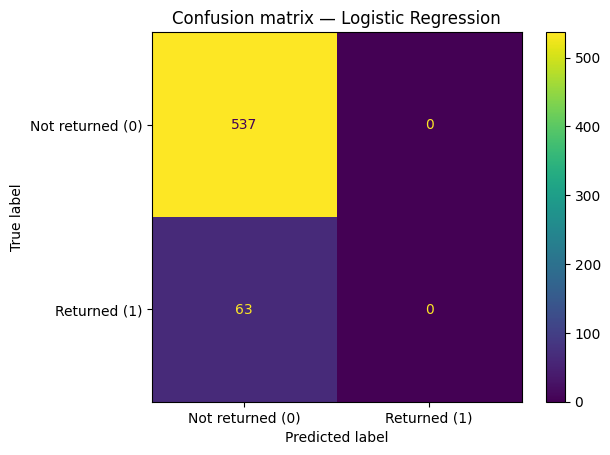

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, class_predictions, labels=[0, 1])
print(cm)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not returned (0)", "Returned (1)"]
)
cm_display.plot(values_format="d")
plt.title("Confusion matrix — Logistic Regression")
plt.show()

### Exercise 9 — Confusion matrix interpretation

1. How many returned orders did the model identify correctly?
2. How many returned orders did it miss?
3. What does a false positive mean for the operations team?
4. What does a false negative mean?
5. Which error might be more costly? Explain what additional business information you would need.

# 10. Understand classification metrics

No single metric describes every aspect of a classifier. Select metrics based on the business problem and the cost of errors.

### Accuracy

\[
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
\]

Accuracy is the share of all predictions that are correct. It can be misleading when classes are imbalanced.

### Precision

\[
Precision = \frac{TP}{TP + FP}
\]

Of the orders flagged as likely returns, what share were actually returned? Higher precision means fewer false alarms among flagged orders.

### Recall

\[
Recall = \frac{TP}{TP + FN}
\]

Of all orders that were returned, what share did the model identify? Higher recall means fewer missed returns.

### F1-score

\[
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
\]

F1 combines precision and recall using their harmonic mean. It is useful when both matter, but it does not include true negatives.

In [13]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)

metrics = {
    "Accuracy": accuracy_score(y_test, class_predictions),
    "Precision": precision_score(y_test, class_predictions, zero_division=0),
    "Recall": recall_score(y_test, class_predictions, zero_division=0),
    "F1-score": f1_score(y_test, class_predictions, zero_division=0)
}

display(pd.DataFrame.from_dict(metrics, orient="index", columns=["Score"]).round(3))
print(classification_report(
    y_test, class_predictions,
    target_names=["Not returned", "Returned"],
    zero_division=0
))

,Score
Accuracy,0.895
Precision,0.000
Recall,0.000
F1-score,0.000


              precision    recall  f1-score   support

Not returned       0.90      1.00      0.94       537
    Returned       0.00      0.00      0.00        63

    accuracy                           0.90       600
   macro avg       0.45      0.50      0.47       600
weighted avg       0.80      0.90      0.85       600



### Read the metrics in business language

- Accuracy answers: "How often was the model correct overall?"
- Precision answers: "When we flag an order, how often is it truly returned?"
- Recall answers: "How many of all returned orders do we successfully flag?"
- F1 answers: "How well do we balance precision and recall?"

For an early-warning workflow, missing a likely return may be more costly than reviewing an order that would not be returned. In that case, recall may deserve more attention. The final choice must be agreed with the business team.

### Exercise 10 — Choose the right metric

For each situation, select the metric that deserves close attention and explain why.

1. The review team has very limited capacity and can inspect only a small number of flagged orders.
2. Missing a return-risk order is expensive, but reviewing extra orders is manageable.
3. The team wants one summary score that balances precision and recall.
4. The dataset has 98% non-returns and 2% returns. Why could accuracy alone be dangerous?

# 11. ROC curve and ROC-AUC

A classifier can be evaluated at many thresholds. The ROC curve plots:

- **True Positive Rate (TPR):** recall
- **False Positive Rate (FPR):** the share of actual negatives incorrectly flagged

The ROC-AUC score summarizes how well the model ranks positive examples above negative examples across thresholds.

AUC is not the same as accuracy, and it does not tell the business which threshold to use. A model with a useful AUC still needs threshold selection and operational review.

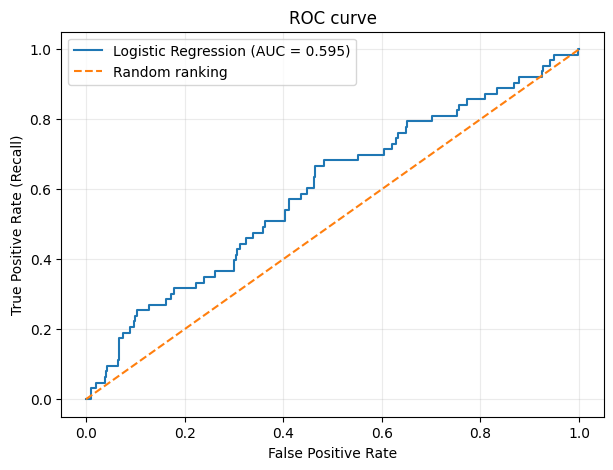

ROC-AUC: 0.595


In [14]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, return_probabilities)
roc_auc = roc_auc_score(y_test, return_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")

### A practical interpretation of AUC

A ROC-AUC of 0.5 indicates ranking performance similar to random ordering. A value closer to 1 indicates stronger ranking separation on the evaluated data.

AUC does not guarantee good probability calibration, good performance for every customer group, or business value. It should be read with other metrics and the use case.

### Exercise 11 — ROC-AUC

1. What does the ROC curve compare?
2. What does an AUC near 0.5 suggest?
3. Does a high AUC identify the best decision threshold?
4. Why should ROC-AUC not replace precision and recall in the business report?

# 12. Choose a decision threshold for the business

The default threshold of 0.50 is a starting point, not a universal business rule.

A lower threshold usually flags more orders. This can increase recall but may also increase false positives. A higher threshold usually flags fewer orders and may improve precision, but can miss more returns.

The correct threshold depends on review capacity and the relative costs of false positives and false negatives.

In [15]:
from sklearn.metrics import precision_recall_fscore_support

threshold_rows = []
for threshold in [0.25, 0.35, 0.45, 0.50, 0.60, 0.70]:
    threshold_labels = (return_probabilities >= threshold).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, threshold_labels, average="binary", zero_division=0
    )
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "orders_flagged": int(threshold_labels.sum())
    })

threshold_comparison = pd.DataFrame(threshold_rows)
display(threshold_comparison.round(3))

,threshold,precision,recall,f1,orders_flagged
0,0.25,0.188,0.048,0.076,16
1,0.35,0.000,0.000,0.000,1
2,0.45,0.000,0.000,0.000,0
3,0.50,0.000,0.000,0.000,0
4,0.60,0.000,0.000,0.000,0
5,0.70,0.000,0.000,0.000,0


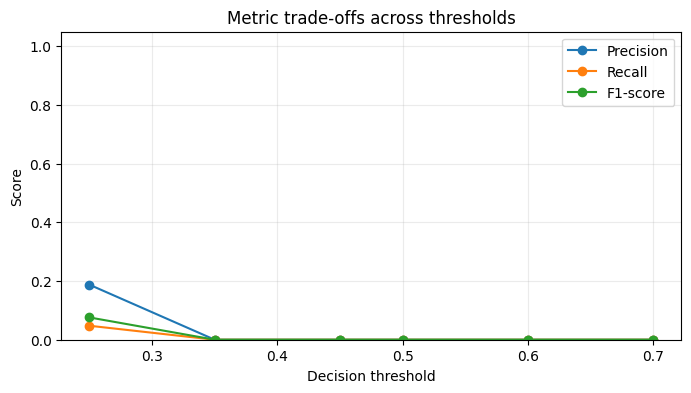

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(threshold_comparison["threshold"], threshold_comparison["precision"],
         marker="o", label="Precision")
plt.plot(threshold_comparison["threshold"], threshold_comparison["recall"],
         marker="o", label="Recall")
plt.plot(threshold_comparison["threshold"], threshold_comparison["f1"],
         marker="o", label="F1-score")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Metric trade-offs across thresholds")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Important evaluation discipline

The threshold comparison above is for learning. In a production workflow, choose the threshold using validation data or a business-approved validation process, then report final performance once on a separate test set.

Do not repeatedly adjust the threshold based on test results and then present that same test score as an unbiased final estimate.

### Exercise 12 — Threshold decision

AdventureWorks can review only 120 orders per week.

1. Which threshold in the table flags a number of orders closest to this capacity after scaling to the test-set size?
2. What happens to recall when the threshold is reduced?
3. What operational risk appears if the team flags too many orders?
4. Recommend a thresholding approach. State the business information you would need before making a final recommendation.

# 13. Common mistakes and professional workflow

### Mistake 1 — Using accuracy alone

A model can predict the majority class and still report high accuracy while missing many positive cases.

### Mistake 2 — Treating probability as certainty

A probability is an estimate. It should be checked for model quality and, when decisions depend on it, calibration.

### Mistake 3 — Using post-outcome information

Fields such as refund amount or return reason are not available at the prediction moment. Including them creates target leakage.

### Mistake 4 — Ignoring class order

Always check `classes_` before selecting a probability column.

### Mistake 5 — Fitting preprocessing on all data

Imputers, scalers, and encoders must be fitted on training data only. A pipeline helps enforce this.

### Mistake 6 — Treating coefficients as causal effects

Coefficients describe model associations under the fitted specification. They do not prove that changing a feature will change return behaviour.

### Mistake 7 — Treating the threshold as a technical constant

The threshold is a decision rule that should reflect business costs and capacity.

### Exercise 13 — Spot the mistake

For each statement, explain what is wrong and how to improve it.

1. "Our model has 94% accuracy, so it is ready to deploy."
2. "We used the refund amount because it strongly predicts returns."
3. "A 0.70 probability means this order will definitely be returned."
4. "We scaled the full dataset before creating the train/test split."
5. "A coefficient is positive, so the feature causes returns."
6. "We selected the threshold that gave the best test-set F1."

# 14. Mini project — AdventureWorks Return-Risk Prioritization

## Business brief

The AdventureWorks operations team wants a model that ranks newly placed orders by estimated return probability. The team will use the ranking to prioritize a limited number of orders for additional review.

Your task is to build a reproducible classification workflow, evaluate it, and communicate its limitations.

### Required tasks

**Part A — Frame the problem**
1. Define the business question and the positive class.
2. Explain why the task is binary classification.
3. List the prediction-time features and identify at least two leakage risks.

**Part B — Build the model**
4. Create a stratified train/test split.
5. Build a preprocessing pipeline for numeric and categorical columns.
6. Train a Logistic Regression classifier.
7. Generate class predictions and positive-class probabilities.

**Part C — Evaluate**
8. Produce a confusion matrix.
9. Calculate accuracy, precision, recall, F1, and ROC-AUC.
10. Compare at least three decision thresholds.
11. Explain which error type is more important for the proposed workflow.

**Part D — Apply**
12. Create a review list of the 20 orders with the highest estimated return probability.
13. Include order ID, probability, predicted class, and actual label for retrospective analysis only.
14. Explain why the actual label would not be available when scoring a genuinely new order.

**Part E — Communicate**
15. Write a 120–180 word business summary with the model's results, one limitation, and a recommendation.

### Acceptance criteria

- The notebook runs from top to bottom.
- The target is not included in the feature matrix.
- No post-outcome fields are used.
- Preprocessing is fitted only on training data.
- The model is evaluated using more than accuracy.
- The threshold choice is explained in business terms.
- The report avoids causal claims and guarantees.

## Mini project — Student workspace

Complete the tasks below. Use the earlier sections as a reference, but write your own code and explanations.

In [17]:
# TODO 1: Define project features and target.
# project_features = [...]
# X_project = orders[project_features].copy()
# y_project = orders["returned"].copy()

# TODO 2: Create a stratified train/test split.

# TODO 3: Build a preprocessing and Logistic Regression pipeline.

# TODO 4: Fit the model and calculate positive-class probabilities.

# TODO 5: Report confusion matrix, precision, recall, F1, and ROC-AUC.

# TODO 6: Create a ranked review list for the highest-risk 20 orders.

### Business report template

Write 120–180 words using this structure:

- **Objective:** What decision does the model support?
- **Data:** What information was used, and what was excluded?
- **Performance:** What do the selected metrics tell us?
- **Operational trade-off:** What does the chosen threshold mean for review capacity?
- **Limitations:** What should the business not conclude?
- **Recommendation:** What should happen before any real deployment?

# 15. Knowledge check

Answer without looking back at the explanations.

1. What makes a problem a binary classification task?
2. What does the positive class represent in this notebook?
3. Why is Logistic Regression used for classification despite its name?
4. What range of values can the sigmoid function return?
5. What is the difference between `predict()` and `predict_proba()`?
6. What does a threshold control?
7. What is a false positive in the AdventureWorks case?
8. What is a false negative?
9. What does precision measure?
10. What does recall measure?
11. Why can accuracy be misleading with imbalanced classes?
12. What does ROC-AUC measure at a high level?
13. Why should we not select a threshold using the final test set?
14. Why are scaling and one-hot encoding included in the pipeline?
15. Why are coefficients not proof of causation?

# 16. Summary and readiness checklist

## Key takeaways

- Classification predicts a category; binary classification predicts one of two classes.
- The target label must match a clearly defined business question.
- Features must be available at the prediction time.
- Logistic Regression estimates probabilities using a sigmoid link.
- A threshold converts probabilities into class decisions.
- Numeric scaling and categorical encoding prepare mixed data for the model.
- A pipeline keeps preprocessing and modeling together.
- A confusion matrix exposes false positives and false negatives.
- Precision, recall, F1, and ROC-AUC describe different aspects of model performance.
- Threshold selection is a business decision as well as a modeling decision.
- Model associations do not prove causation.

## Ready to move forward?

- [ ] I can distinguish regression from classification.
- [ ] I can define a positive class and select valid features.
- [ ] I can explain probabilities and decision thresholds.
- [ ] I can train a Logistic Regression classifier.
- [ ] I can interpret a confusion matrix.
- [ ] I can explain accuracy, precision, recall, F1, and ROC-AUC.
- [ ] I can describe the trade-off between false positives and false negatives.
- [ ] I can explain why leakage and test-set tuning are dangerous.
- [ ] I can communicate model results with appropriate limitations.

## Suggested next step

The next classification session should build on these foundations by comparing classification algorithms and decision boundaries, then evaluating how model complexity affects generalization. Avoid repeating the Logistic Regression fundamentals taught here.

# Instructor solutions — selected exercises

> **Instructor-only section.** Keep this section in the trainer master copy. Remove or hide it before distributing a student-only version if required.

## Exercise 1 — Suggested answers

1. The output is one of two categories: returned or not returned.
2. Class `1` means returned.
3. Examples include order value, product category, channel, discount, and customer tenure.
4. Refund amount is only known after a return or refund process and leaks the outcome.
5. Operations or customer support may prioritize orders for review, but the score should not automatically trigger unfair treatment.

## Exercise 2 — Suggested answers

- The dataset contains 2,400 orders.
- Missing values were introduced in `unit_price`, `customer_segment`, and `days_since_last_order`.
- The class distribution should be read from the generated output; it is not assumed to be balanced.
- Class proportions affect the usefulness of accuracy and the evaluation strategy.
- Numeric examples: `quantity`, `unit_price`. Categorical examples: `product_category`, `sales_channel`.

## Exercise 3 — Suggested answers

- `order_id` identifies a row and is not a stable behavioural signal.
- `return_reason` is only known after the return and is leakage.
- Valid hypothetical features include the promotion type shown at checkout or the selected delivery option, if known at prediction time.
- A feature is an input; the target is the outcome to predict.

## Exercise 4 — Suggested answers

- Probability is the model's estimated chance for a class; a predicted class is the decision after applying a threshold.
- At 0.50, probability 0.49 maps to class 0.
- Increasing the threshold usually reduces positive predictions.
- A lower threshold may catch more potential returns.
- It may also create more false positives and increase review workload.
- 0.80 is a model estimate, not a guarantee for an individual order.

## Exercise 5 — Suggested answers

- Logistic Regression models class probabilities using a logistic link.
- A positive coefficient increases estimated log-odds, holding other modeled features constant.
- Observational data and model coefficients do not establish causality.
- If odds are 2, probability is 2 / (1 + 2) = 0.667.

## Exercise 6 — Suggested answers

- Imputation fills missing feature values so the estimator can process the data.
- Scaling places numeric features on comparable scales and supports stable optimization.
- One-hot encoding represents categories as numeric indicator columns.
- `handle_unknown="ignore"` avoids an error when a new category appears at prediction time.
- A pipeline keeps transformations consistent and fits them within each training workflow.
- Fitting on the full dataset lets information from the test set influence preprocessing.

## Exercise 7 — Suggested answers

- `fit()` receives `X_train` and `y_train`.
- `y_test` is held back for evaluation.
- Training success does not prove generalization.
- Check feature scales, data quality, solver settings, and `max_iter`.

## Exercise 8 — Suggested answers

- `predict()` returns class labels.
- `predict_proba()` returns class probabilities.
- `classes_` confirms the probability column order.
- A probability near 0.50 indicates the model is near its current decision boundary.
- A high probability is not a guarantee.

## Exercise 9 — Suggested answers

- True positives are the bottom-right cell of the matrix when labels are ordered [0, 1].
- False negatives are actual positives predicted as 0.
- False positives create unnecessary review work.
- False negatives are returned orders that were not flagged.
- The relative cost depends on review cost, return cost, customer impact, and operational capacity.

## Exercise 10 — Suggested answers

1. Precision is important because the review team needs fewer false alarms.
2. Recall is important because missing returns is expensive.
3. F1 is a single balance of precision and recall.
4. A majority-class predictor could achieve high accuracy while failing to identify the rare positive class.

## Exercise 11 — Suggested answers

- ROC plots true positive rate against false positive rate at different thresholds.
- AUC near 0.5 indicates ranking similar to random.
- AUC does not choose a business threshold.
- Precision and recall explain the positive-class consequences at a selected threshold.

## Exercise 12 — Suggested answers

There is no universal threshold without knowing the costs of false positives and false negatives. Learners should use the threshold table to compare the flagged volume and metric trade-offs, then explain how a validation process and real weekly volume are needed before choosing an operational policy.

## Exercise 13 — Suggested answers

1. Accuracy alone may hide poor positive-class recall; inspect confusion matrix, precision, recall, F1, and class balance.
2. Refund amount is post-outcome leakage; use only information available at prediction time.
3. Probability is not certainty; it is an estimated likelihood.
4. Split first, then fit preprocessing on training data through a pipeline.
5. Coefficients show conditional associations, not causation.
6. Threshold selection on the test set overfits the evaluation set; use validation data and reserve the test set for final evaluation.

## Mini project — evaluation rubric

| Criterion | Points |
|---|---:|
| Correct problem framing and leakage control | 15 |
| Reproducible split and preprocessing pipeline | 20 |
| Correct Logistic Regression training and prediction | 15 |
| Confusion matrix and suitable metrics | 20 |
| Threshold analysis and business reasoning | 15 |
| Clear report, limitations, and recommendation | 15 |
| **Total** | **100** |

## Instructor delivery notes

- Ask learners to explain false positives and false negatives using the returns workflow, not only definitions.
- Do not present the synthetic feature relationships as real business findings.
- Emphasize that the positive class is explicitly class `1`.
- Ask learners to check `classes_` before interpreting probability columns.
- Keep the threshold discussion focused on operational cost and capacity.
- If learners ask whether Logistic Regression is a regression model, explain that its name refers to the logistic model of the log-odds; its common scikit-learn use here is classification.

## Technical references

- [Scikit-learn — LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [Scikit-learn — Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)
- [Scikit-learn — Confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
- [Scikit-learn — ROC curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html)
- [Scikit-learn — ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
- [Scikit-learn — Pipelines](https://scikit-learn.org/stable/modules/compose.html)

**End of ML_10 — Logistic Regression & Classification Fundamentals**